# La brecha del ICFES en Caldas

**Taller en Ciencia de Datos y Aprendizaje Automático** · Especialización en Estadística · UNAL Manizales · 2026-II
Profesor: Carlos Manuel Orrego Franco

Este cuaderno lo resuelvo yo en vivo. Ustedes lo siguen, lo corren y me interrumpen. Termina, como *El IPC del sancocho*, en un carrusel para LinkedIn.

| Ficha | |
|---|---|
| **Objetivo pedagógico** | Limpiar un dato de personas dejando cada decisión a la vista, escoger una métrica que responda a la decisión del cliente, revisar a quién le falla el modelo y contar el resultado. |
| **Enfoque** | Ciencia de Datos. |
| **Resultados de aprendizaje** | 1 (formular), 2 (seleccionar y preparar datos), 4 (implementar y evaluar), 5 (comunicar) y 6 (reflexión ética). |
| **Uso de IA** | Pueden pedirle a Claude que explique una línea o que escriba una gráfica. Deben poder explicar sin ayuda por qué la exactitud engaña aquí, qué es la captación y por qué la partición se hace por colegio. |
| **Entregable** | Este cuaderno corrido en su portafolio, con las predicciones y la decisión en tres frases. |

In [47]:
# Celda de arranque. No hay que cambiarle nada: trae las herramientas del curso.
import pathlib, subprocess, sys
raiz = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.cwd() / "taller-cd-ml-2026-2"] if (p / "taller" / "datos.py").exists()), None)
if raiz is None:
    subprocess.run(["git", "clone", "-q", "https://github.com/cmorregof/taller-cd-ml-2026-2.git"], check=True)
    raiz = pathlib.Path("taller-cd-ml-2026-2")
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from taller import descargar, procedencia

PALETA = ["#1D4E89", "#D7263D", "#1B998B", "#6C4AB6", "#5BC0EB", "#F49097", "#9AA5B1"]      # colores del curso
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=PALETA), "axes.titleweight": "bold", "figure.dpi": 110})
print("Herramientas listas.")

Herramientas listas.


## 1. La pregunta

La Secretaría de Educación de Caldas tiene un programa de refuerzo para grado once. El presupuesto alcanza para uno de cada cuatro estudiantes, y los cupos se reparten antes del examen, cuando solo se sabe lo que cada uno respondió en la inscripción.

1. **Predecir.** ¿Qué estudiantes van a quedar en el cuarto más bajo del país?
2. **Explicar.** ¿Qué condiciones del hogar y del colegio acompañan ese resultado?
3. **Decidir.** Con cupo para el 25 %, ¿a quiénes se les ofrece el refuerzo, y a quiénes deja por fuera esa regla?

**El dato.** Saber 11, aplicación 2020-2, publicado por el ICFES en datos.gov.co. Cada fila es un estudiante anonimizado, con su puntaje, sus respuestas sobre el hogar y los datos de su colegio.

**La respuesta.** $y_i=1$ si el percentil nacional del estudiante $i$ es 25 o menos.

**La métrica.** Si el modelo ordena a los estudiantes por riesgo y el programa atiende al primer 25 %, la **captación** es la fracción de los que quedaron abajo que recibió cupo:

$$\text{captación}=\frac{\#\{i:\ y_i=1\ \text{y}\ i\ \text{recibe cupo}\}}{\#\{i:\ y_i=1\}}.$$

### Predicción escrita

- En Caldas, ¿qué fracción de los estudiantes queda en el cuarto más bajo del país? **Mi apuesta:**
- ¿Qué pesa más: el colegio, la zona o la familia? **Mi apuesta:**
- Si los cupos se reparten por sorteo, ¿cuál es la captación? **Mi apuesta:**

### Predicción escrita

- **Mi apuesta:** Del 8% al 12%
- **Mi apuesta:** La zona, el colegio y la familia, en ese orden
- **Mi apuesta:** La captación sería del 6,125[texto del vínculo](https://)%

### Recursos de Plomería

In [48]:
"""Plomería del cuaderno «La brecha del ICFES»: variables, tramos por colegio, captación,
competencia de candidatos y auditoría por grupos.

    from taller.icfes import preparar, tasa_por, tramos, competir, asignar_cupos, auditar
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import NearestCentroid

EDUCACION = {
    "Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2,
    "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
    "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
    "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9,
}
LIBROS = {"0 A 10 LIBROS": 0, "11 A 25 LIBROS": 1, "26 A 100 LIBROS": 2, "MÁS DE 100 LIBROS": 3}
PERSONAS = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9}
CUARTOS = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}
LECTURA = {"No leo por entretenimiento": 0, "30 minutos o menos": 1, "Entre 30 y 60 minutos": 2,
           "Entre 1 y 2 horas": 3, "Más de 2 horas": 4}
TRABAJO = {"0": 0, "Menos de 10 horas": 1, "Entre 11 y 20 horas": 2, "Entre 21 y 30 horas": 3, "Más de 30 horas": 4}


def preparar(crudo: pd.DataFrame, edad_minima: int = 13, edad_maxima: int = 70):
    """Convierte las respuestas del formulario en números. Solo se usa lo que se sabe en la inscripción.

    Devuelve X (variables), y (1 si quedó en el cuarto más bajo del país), el código del colegio
    y la tabla original, sin los estudiantes con puntaje global igual a cero.
    """
    edad = 2020 - pd.to_numeric(crudo["estu_fechanacimiento"].astype(str).str[:4], errors="coerce")
    si = lambda col: (crudo[col] == "Si").astype(float).where(crudo[col].notna())
    X = pd.DataFrame(index=crudo.index)
    X["mujer"] = (crudo["estu_genero"] == "F").astype(float).where(crudo["estu_genero"].notna())
    X["edad"] = edad.where(edad.between(edad_minima, edad_maxima))
    X["etnia"] = si("estu_tieneetnia")
    X["estrato"] = pd.to_numeric(crudo["fami_estratovivienda"].str.extract(r"(\d)")[0], errors="coerce")
    X["sin_estrato"] = (crudo["fami_estratovivienda"] == "Sin Estrato").astype(float)
    X["educacion_madre"] = crudo["fami_educacionmadre"].map(EDUCACION)
    X["educacion_padre"] = crudo["fami_educacionpadre"].map(EDUCACION)
    for cosa in ["internet", "computador", "automovil"]:
        X[cosa] = si(f"fami_tiene{cosa}")
    X["libros"] = crudo["fami_numlibros"].map(LIBROS)
    X["personas_hogar"] = crudo["fami_personashogar"].map(PERSONAS)
    X["cuartos"] = crudo["fami_cuartoshogar"].map(CUARTOS)
    X["lectura_diaria"] = crudo["estu_dedicacionlecturadiaria"].map(LECTURA)
    X["horas_trabajo"] = crudo["estu_horassemanatrabaja"].astype(str).map(TRABAJO)
    X["colegio_oficial"] = (crudo["cole_naturaleza"] == "OFICIAL").astype(float)
    X["colegio_rural"] = (crudo["cole_area_ubicacion"] == "RURAL").astype(float)
    X["nocturna_o_sabatina"] = crudo["cole_jornada"].isin(["NOCHE", "SABATINA"]).astype(float)
    X["jornada_completa"] = crudo["cole_jornada"].isin(["COMPLETA", "UNICA"]).astype(float)

    y = (pd.to_numeric(crudo["percentil_global"], errors="coerce") <= 25).astype(int).rename("bajo")
    colegio = crudo["cole_cod_dane_establecimiento"]
    validas = pd.to_numeric(crudo["punt_global"], errors="coerce") > 0
    return X[validas], y[validas], colegio[validas], crudo[validas]


def tasa_por(y: pd.Series, grupo: pd.Series, orden: list | None = None) -> pd.DataFrame:
    """Porcentaje en el cuarto más bajo del país por grupo, con su error estándar."""
    tabla = pd.DataFrame({"n": y.groupby(grupo).size(), "tasa": y.groupby(grupo).mean() * 100})
    tabla["ee"] = np.sqrt(tabla["tasa"] * (100 - tabla["tasa"]) / tabla["n"])
    return tabla.reindex(orden).dropna() if orden else tabla.sort_values("tasa")


def tramos(X: pd.DataFrame, y: pd.Series, colegio: pd.Series, semilla: int = 0):
    """Entrenamiento, validación y prueba, con colegios enteros en cada tramo (60 / 20 / 20)."""
    resto, prueba = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semilla).split(X, y, colegio))
    entrena, valida = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=semilla)
                           .split(X.iloc[resto], y.iloc[resto], colegio.iloc[resto]))
    E, V, P = (np.zeros(len(X), dtype=bool) for _ in range(3))
    E[resto[entrena]] = True
    V[resto[valida]] = True
    P[prueba] = True
    return E, V, P


def captacion(real, puntaje, cupo: float = 0.25) -> float:
    """Fracción de los que quedaron abajo que cae entre los primeros `cupo` del orden. Empates por sorteo."""
    real, puntaje = np.asarray(real), np.asarray(puntaje, dtype=float)
    k = int(round(cupo * len(real)))
    orden = np.lexsort((np.random.default_rng(0).random(len(real)), -puntaje))
    return float(real[orden[:k]].sum() / real.sum())


def modelos() -> dict:
    llenar = lambda: SimpleImputer(strategy="median")
    return {
        "logística": make_pipeline(llenar(), StandardScaler(), LogisticRegression(max_iter=1000)),
        "árbol": make_pipeline(llenar(), DecisionTreeClassifier(max_depth=5, random_state=0)),
        "bosque": make_pipeline(llenar(), RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                                  random_state=0, n_jobs=-1)),
        "vecinos más cercanos": make_pipeline(llenar(), StandardScaler(), NearestCentroid()),

    }


def competir(X, y, E, V, P, cupo: float = 0.25):
    """Dos reglas sin modelo y tres modelos. Se escoge en validación y se reporta en prueba.

    Devuelve la tabla de resultados y el puntaje de riesgo que cada candidato da en la prueba.
    """
    mediana_madre = X.loc[E, "educacion_madre"].median()
    reglas = {
        "sorteo": pd.Series(np.random.default_rng(1).random(len(X)), index=X.index),
        "regla: educación de la madre": -X["educacion_madre"].fillna(mediana_madre),
    }
    tabla, puntajes = {}, {}
    for nombre, regla in reglas.items():
        puntajes[nombre] = regla[P]
        tabla[nombre] = {"captación en validación": captacion(y[V], regla[V], cupo),
                         "captación en prueba": captacion(y[P], regla[P], cupo),
                         "AUC en prueba": roc_auc_score(y[P], regla[P])}
    for nombre, modelo in modelos().items():
        modelo.fit(X[E], y[E])
        en_validacion = captacion(y[V], modelo.predict_proba(X[V])[:, 1], cupo)
        modelo.fit(X[E | V], y[E | V])
        puntajes[nombre] = pd.Series(modelo.predict_proba(X[P])[:, 1], index=X.index[P])
        tabla[nombre] = {"captación en validación": en_validacion,
                         "captación en prueba": captacion(y[P], puntajes[nombre], cupo),
                         "AUC en prueba": roc_auc_score(y[P], puntajes[nombre])}
    return pd.DataFrame(tabla).T, puntajes


def asignar_cupos(puntaje: pd.Series, cupo: float = 0.25) -> pd.Series:
    """Marca con True a los primeros `cupo` del orden de riesgo."""
    k = int(round(cupo * len(puntaje)))
    orden = np.lexsort((np.random.default_rng(0).random(len(puntaje)), -puntaje.values))
    marcado = pd.Series(False, index=puntaje.index)
    marcado.iloc[orden[:k]] = True
    return marcado


def auditar(y: pd.Series, cupos: pd.Series, grupo: pd.Series) -> pd.DataFrame:
    """Por grupo: cuántos quedaron abajo, cuántos recibieron cupo y qué fracción de los de abajo lo recibió."""
    grupo = grupo.loc[cupos.index]
    filas = {}
    for valor, indices in grupo.groupby(grupo).groups.items():
        yy, cc = y.loc[indices], cupos.loc[indices]
        filas[valor] = {"n": len(yy), "% que quedó abajo": yy.mean() * 100, "% con cupo": cc.mean() * 100,
                        "captación": cc[yy == 1].mean()}
    return pd.DataFrame(filas).T

## 2. Tres trampas antes de modelar

**Edades imposibles.** La fecha de nacimiento trae errores de digitación.

In [76]:
#from taller.icfes import preparar, tasa_por, tramos, competir, asignar_cupos, auditar

DEPARTAMENTO = "RISARALDA"      # al final pueden cambiarlo por otro departamento
CUPO = 0.25
crudo = descargar("saber11", departamento=DEPARTAMENTO)
print(f"{len(crudo):,} estudiantes de {crudo['cole_cod_dane_establecimiento'].nunique()} colegios".replace(",", "."))

[saber11] Descargo de la fuente oficial: ICFES, en datos.gov.co, conjunto rnvb-vnyh.
[saber11] Listo: 9.326 filas.
9.326 estudiantes de 192 colegios


In [77]:
edad = 2020 - pd.to_numeric(crudo["estu_fechanacimiento"].astype(str).str[:4], errors="coerce") ## Coerce pone como Nan los que tengan error de digitación
print("Edades fuera de 13 a 70 años:", int((~edad.between(13, 70)).sum()))

Edades fuera de 13 a 70 años: 3


**Puntajes en cero.** Un puntaje global de cero es sospechoso en un examen de cinco pruebas. Miremos cuántos hay y en qué estado los publica el ICFES.

In [78]:
puntaje = pd.to_numeric(crudo["punt_global"], errors="coerce")
print("Puntaje global igual a cero:", int((puntaje == 0).sum()))
print(crudo.loc[puntaje == 0, "estu_estadoinvestigacion"].value_counts().to_string())

Puntaje global igual a cero: 0
Series([], )


**Faltantes que no son al azar.** Quienes dejan preguntas en blanco no se parecen a los demás. Si borráramos esas filas, la muestra quedaría más privilegiada de lo que es. Por eso no se borran: los modelos llenan los huecos con la mediana del entrenamiento, y lo decimos.

`preparar` convierte el formulario en números, deja las edades imposibles como faltantes y quita solo los puntajes en cero, porque no describen un desempeño. Es una decisión, y va a la bitácora.

In [79]:
X, y, colegio, datos = preparar(crudo)
incompleta = X.isna().any(axis=1)
print(f"Quedan {len(X):,} estudiantes. En el cuarto más bajo del país: {y.mean() * 100:.1f} %".replace(",", "."))
print(f"Con algún faltante: {incompleta.mean() * 100:.1f} % | de ellos, en el cuarto más bajo: {y[incompleta].mean() * 100:.1f} %")

Quedan 9.326 estudiantes. En el cuarto más bajo del país: 20.5 %
Con algún faltante: 15.9 % | de ellos, en el cuarto más bajo: 24.8 %


In [80]:
help(preparar)

Help on function preparar in module __main__:

preparar(
    crudo: 'pd.DataFrame',
    edad_minima: 'int' = 13,
    edad_maxima: 'int' = 70
)
    Convierte las respuestas del formulario en números. Solo se usa lo que se sabe en la inscripción.

    Devuelve X (variables), y (1 si quedó en el cuarto más bajo del país), el código del colegio
    y la tabla original, sin los estudiantes con puntaje global igual a cero.



## 3. La brecha

Antes de cualquier modelo, la pregunta descriptiva: ¿en qué grupos se concentran los puntajes bajos? Las barras llevan dos errores estándar, para no leer diferencias donde hay ruido.

In [81]:
datos.head(10) #Mostrar los primeros 10
datos.tail()   #Mostrar los últimos 5

,estu_consecutivo,estu_genero,estu_fechanacimiento,estu_nacionalidad,estu_tieneetnia,fami_estratovivienda,fami_personashogar,fami_cuartoshogar,fami_educacionpadre,fami_educacionmadre,...,punt_sociales_ciudadanas,punt_ingles,desemp_matematicas,punt_global,percentil_global,estu_inse_individual,estu_nse_individual,estu_nse_establecimiento,estu_estadoinvestigacion,estu_generacion_e
9321,SB11202040576603,M,2003-07-23T00:00:00.000,COLOMBIA,NaN,Estrato 2,3 a 4,Dos,Primaria incompleta,Primaria completa,...,34,33,3,227,37,43.669772,2.0,3.0,PUBLICAR,NO
9322,SB11202040576606,F,2003-08-24T00:00:00.000,COLOMBIA,NaN,Estrato 2,1 a 2,Dos,Educación profesional incompleta,Técnica o tecnológica completa,...,62,53,1,264,63,63.547322,3.0,3.0,PUBLICAR,NO
9323,SB11202040576615,F,2004-03-01T00:00:00.000,COLOMBIA,NaN,Estrato 1,3 a 4,Dos,Secundaria (Bachillerato) completa,Primaria completa,...,71,67,4,347,98,50.927435,2.0,3.0,PUBLICAR,NO
9324,SB11202040576616,F,2003-08-21T00:00:00.000,COLOMBIA,NaN,Estrato 2,3 a 4,Tres,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,...,58,58,3,300,85,55.509986,3.0,3.0,PUBLICAR,NO
9325,SB11202040576628,M,2004-01-16T00:00:00.000,COLOMBIA,NaN,Estrato 2,5 a 6,Cuatro,Primaria incompleta,Secundaria (Bachillerato) completa,...,48,57,3,269,67,58.492202,3.0,3.0,PUBLICAR,NO


In [82]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9326 entries, 0 to 9325
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   estu_consecutivo               9326 non-null   object 
 1   estu_genero                    9326 non-null   object 
 2   estu_fechanacimiento           9326 non-null   object 
 3   estu_nacionalidad              9326 non-null   object 
 4   estu_tieneetnia                9246 non-null   object 
 5   fami_estratovivienda           9096 non-null   object 
 6   fami_personashogar             9095 non-null   object 
 7   fami_cuartoshogar              9078 non-null   object 
 8   fami_educacionpadre            9120 non-null   object 
 9   fami_educacionmadre            9121 non-null   object 
 10  fami_tieneinternet             9107 non-null   object 
 11  fami_tienecomputador           9011 non-null   object 
 12  fami_tieneautomovil            9053 non-null   o

In [83]:
puntajes_materias =["punt_lectura_critica", "punt_matematicas", "punt_c_naturales", "punt_sociales_ciudadanas",
"punt_ingles", "punt_global", "percentil_global"]

In [84]:
datos_puntajes = datos[puntajes_materias]
datos_puntajes.describe()

,punt_lectura_critica,punt_matematicas,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles,punt_global,percentil_global
count,9326.000000,9326.000000,9326.000000,9326.000000,9326.000000,9326.000000,9326.000000
mean,53.151190,51.589427,49.192044,49.434806,48.550504,253.330045,53.412288
std,9.785106,11.108188,9.999813,11.615095,11.351502,46.579621,27.751888
min,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,1.000000
25%,46.000000,44.000000,42.000000,40.000000,41.000000,218.000000,30.000000
50%,53.000000,52.000000,49.000000,49.000000,47.000000,252.000000,55.000000
75%,60.000000,59.000000,56.000000,58.000000,54.000000,285.000000,77.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,447.000000,100.000000


Notamos senda asimetría en la distribución de los puntajes. Ya que hay **2485** estudiantes cuyos puntajes están entre (25,215), es decir en un espectro de **190 puntos.**
Luego tenemos **2485** estudiantes entre (215,247), en un diámetro de **32 puntos**
En el tercer cuartil tenemos **2485** estudiantes entre (247,283), en **36 puntos**
Por otro lado tenemos **2485** estudiantes entre (283,452), acá la amplitud del intervalo es de **169 puntos**


De acá se puede analizar que la misma cantidad de estudiantes distribuidos en intervalos de puntajes que no son equitativos. En este sentido el 25% de los mejores puntajes se distribuye en una región más basta que el 50% de los datos que están entre el P25 y el P75

<Axes: >

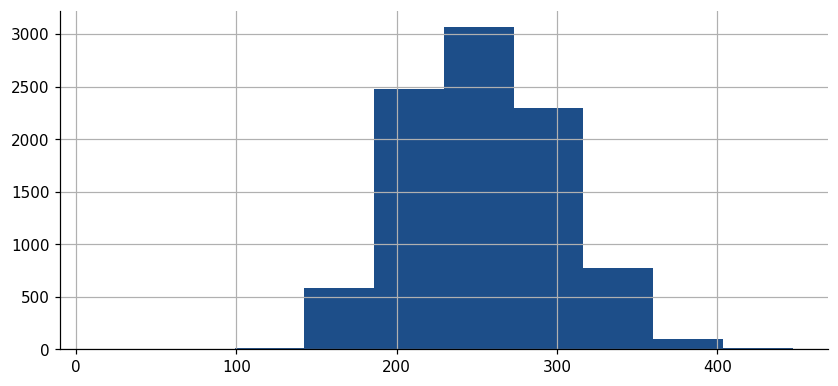

In [85]:
datos_puntajes['punt_global'].hist()

<Axes: xlabel='punt_global', ylabel='Count'>

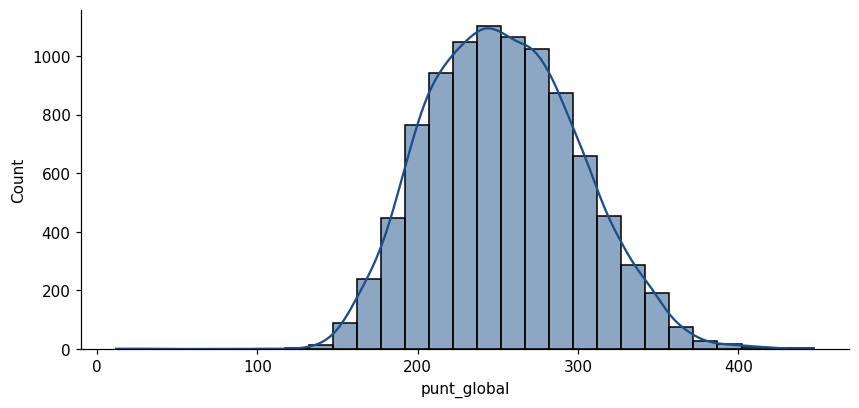

In [86]:
import seaborn as sns
sns.histplot(datos_puntajes, x='punt_global', binwidth = 15, kde = True)

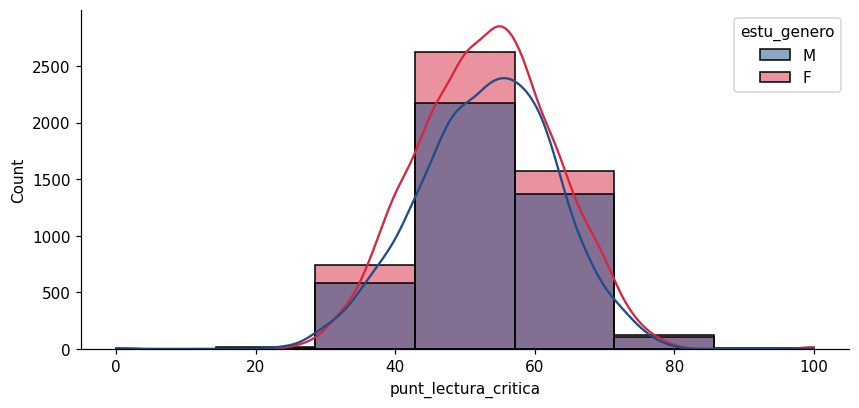

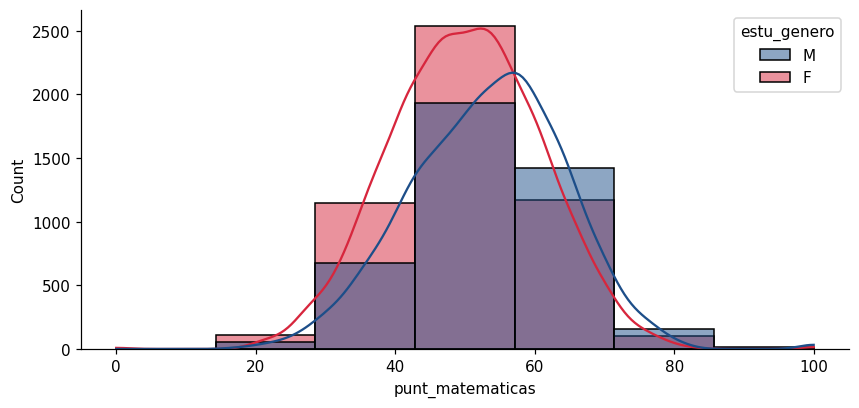

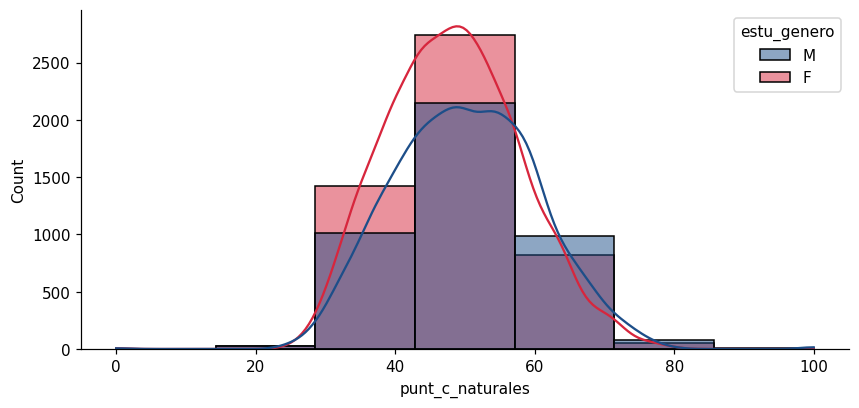

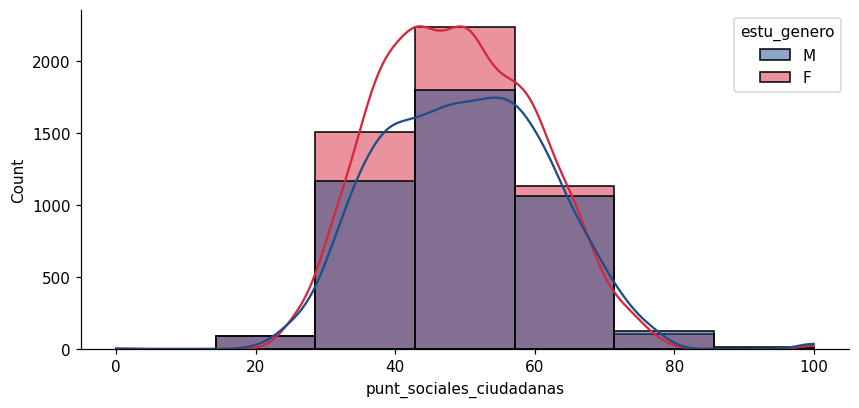

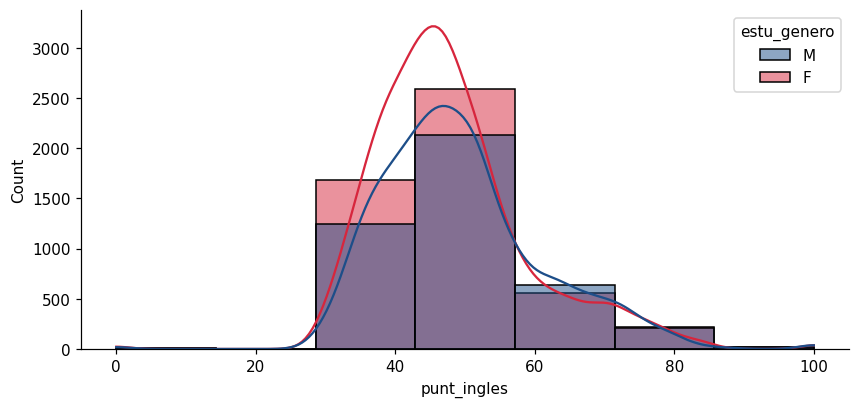

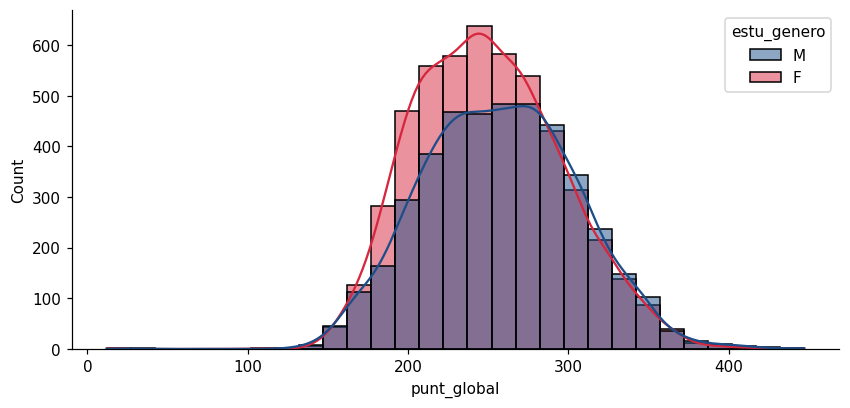

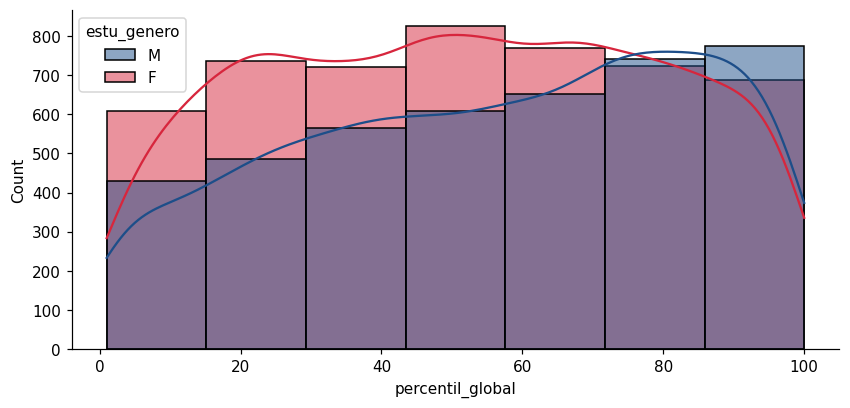

In [87]:
for i in puntajes_materias:
  plt.plot()
  sns.histplot(datos, x = i, hue = 'estu_genero', binwidth = 15, kde = True )
  plt.show()

In [88]:
452-283

169

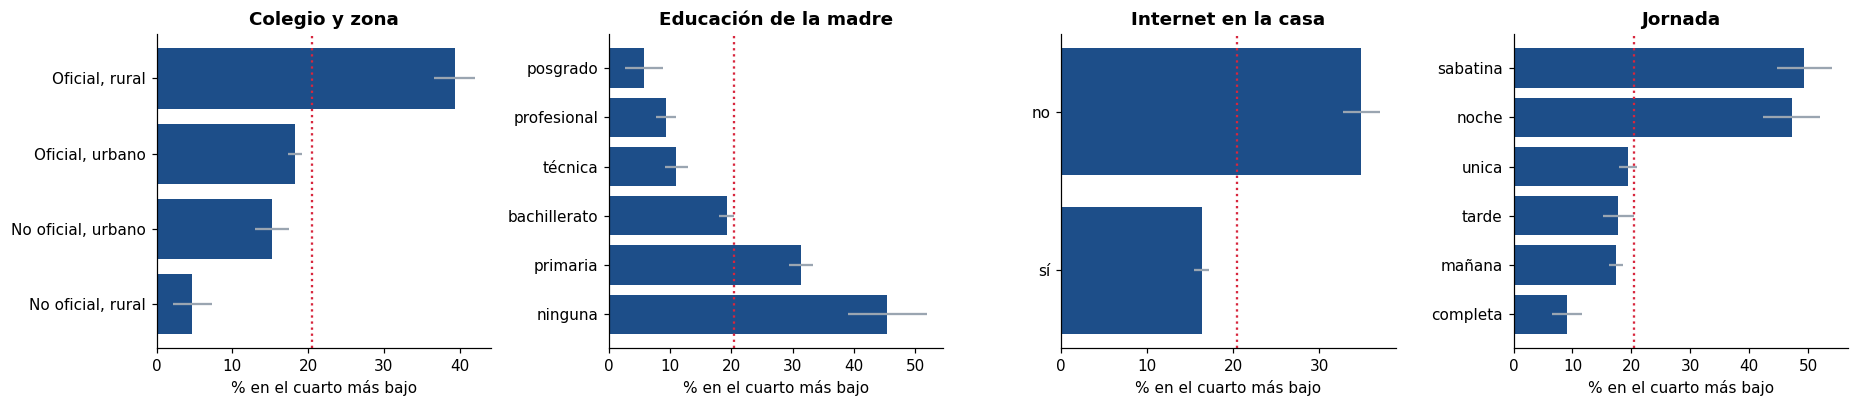

In [89]:
madre = {"Ninguno": "ninguna", "Primaria incompleta": "primaria", "Primaria completa": "primaria",
         "Secundaria (Bachillerato) incompleta": "bachillerato", "Secundaria (Bachillerato) completa": "bachillerato",
         "Técnica o tecnológica incompleta": "técnica", "Técnica o tecnológica completa": "técnica",
         "Educación profesional incompleta": "profesional", "Educación profesional completa": "profesional",
         "Postgrado": "posgrado"}
paneles = {
    "Colegio y zona": tasa_por(y, datos["cole_naturaleza"].str.capitalize() + ", " + datos["cole_area_ubicacion"].str.lower()),
    "Educación de la madre": tasa_por(y, datos["fami_educacionmadre"].map(madre),
                                      ["ninguna", "primaria", "bachillerato", "técnica", "profesional", "posgrado"]),
    "Internet en la casa": tasa_por(y, datos["fami_tieneinternet"].map({"Si": "sí", "No": "no"})),
    "Jornada": tasa_por(y, datos["cole_jornada"].str.lower()),
}
fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))
for eje, (titulo, tabla) in zip(ejes, paneles.items()):
    eje.barh(tabla.index, tabla["tasa"], xerr=2 * tabla["ee"], color=PALETA[0], ecolor="#9AA5B1")
    eje.axvline(y.mean() * 100, color="#D7263D", ls=":"); eje.set(title=titulo, xlabel="% en el cuarto más bajo")
plt.tight_layout(); plt.show()

In [90]:
municipios = tasa_por(y, datos["cole_mcpio_ubicacion"].str.title())
municipios = municipios[municipios["n"] >= 80]
print("Municipios con 80 estudiantes o más, del más alto al más bajo en el cuarto inferior del país:")
print(municipios.sort_values("tasa", ascending=False)[["n", "tasa"]].round(1).to_string())

Municipios con 80 estudiantes o más, del más alto al más bajo en el cuarto inferior del país:
                         n  tasa
cole_mcpio_ubicacion            
Pueblo Rico            147  66.0
Mistrató               114  58.8
La Virginia            217  38.7
Quinchía               290  37.6
Guática                165  37.6
Apía                   130  36.2
Belén De Umbría        247  35.2
Marsella               151  30.5
Santuario              112  17.0
Pereira               4932  16.9
Santa Rosa De Cabal    733  16.2
Dosquebradas          1954  14.9


**Lectura.** Las brechas más grandes aparecen en lo que hay en la casa y en dónde queda el colegio. La diferencia entre colegio oficial y privado es menor. La jornada sabatina y la nocturna agrupan a muchos adultos que validan el bachillerato, y por eso conviene leerlas aparte. Ninguna de estas barras es una causa: son grupos que se superponen.

## 4. Predecir: ¿a quién le llega el cupo?

**Los tramos se parten por colegio.** Dos estudiantes del mismo colegio se parecen. Si uno queda en entrenamiento y el otro en prueba, el modelo parece mejor de lo que es. Por eso cada colegio va entero a un solo tramo: 60 % para entrenar, 20 % para escoger y 20 % para reportar.

Compiten cinco candidatos: el sorteo, una regla de una sola columna (la educación de la madre) y tres modelos (regresión logística, un árbol y un bosque aleatorio).

In [91]:
E, V, P = tramos(X, y, colegio)
todos, puntajes = competir(X, y, E, V, P, CUPO)
display(todos.sort_values("captación en validación", ascending=False).round(3))
print(f"Techo de la captación con cupo del {CUPO:.0%}: {min(1, CUPO / y[P].mean()):.2f}")

,captación en validación,captación en prueba,AUC en prueba
bosque,0.529,0.545,0.765
vecinos más cercanos,0.499,0.482,0.740
logística,0.486,0.533,0.753
árbol,0.461,0.476,0.711
regla: educación de la madre,0.377,0.348,0.607
sorteo,0.271,0.245,0.471


Techo de la captación con cupo del 25%: 1.00


In [92]:
help(tramos)
help(competir)

Help on function tramos in module __main__:

tramos(
    X: 'pd.DataFrame',
    y: 'pd.Series',
    colegio: 'pd.Series',
    semilla: 'int' = 0
)
    Entrenamiento, validación y prueba, con colegios enteros en cada tramo (60 / 20 / 20).

Help on function competir in module __main__:

competir(X, y, E, V, P, cupo: 'float' = 0.25)
    Dos reglas sin modelo y tres modelos. Se escoge en validación y se reporta en prueba.

    Devuelve la tabla de resultados y el puntaje de riesgo que cada candidato da en la prueba.



In [93]:
mejor = todos.drop(index="sorteo")["captación en validación"].idxmax()
regla = "regla: educación de la madre"
elegido = mejor if todos.loc[mejor, "captación en prueba"] > todos.loc[regla, "captación en prueba"] else regla
print(f"Ganador en validación: {mejor} | se usa: {elegido}")
print(f"Captación en prueba: {todos.loc[elegido, 'captación en prueba']:.2f} "
      f"| regla de una columna: {todos.loc[regla, 'captación en prueba']:.2f} | sorteo: {todos.loc['sorteo', 'captación en prueba']:.2f}")

Ganador en validación: bosque | se usa: bosque
Captación en prueba: 0.55 | regla de una columna: 0.35 | sorteo: 0.25


**Por qué no la exactitud.** Un modelo que dijera «nadie queda abajo» acertaría en tres de cada cuatro estudiantes y no le serviría de nada a la Secretaría. La captación mide lo que importa: cuántos de los que necesitaban el cupo lo recibieron.

## 5. ¿A quién le falla?

Repartimos los cupos con el candidato elegido y miramos, por grupo, qué fracción de los que quedaron abajo recibió cupo.

In [94]:
cupos = asignar_cupos(puntajes[elegido], CUPO)
grupos = {"zona": datos["cole_area_ubicacion"].str.lower(),
          "sexo": datos["estu_genero"].map({"F": "mujeres", "M": "hombres"}),
          "jornada": X["nocturna_o_sabatina"].map({1.0: "nocturna o sabatina", 0.0: "diurna"})}
auditoria = pd.concat({nombre: auditar(y, cupos, grupo) for nombre, grupo in grupos.items()})
auditoria.round({"n": 0, "% que quedó abajo": 1, "% con cupo": 1, "captación": 2})

n  % que quedó abajo  % con cupo  captación
zona    rural                 248.0               27.8        46.4       0.78
        urbano               1306.0               20.0        20.9       0.48
sexo    hombres               721.0               17.1        18.0       0.41
        mujeres               833.0               24.8        31.0       0.62
jornada diurna               1242.0               15.7        12.0       0.31
        nocturna o sabatina   312.0               43.3        76.6       0.89

Una captación más baja en un grupo significa que el programa deja por fuera, en proporción, a más estudiantes de ese grupo que lo necesitaban. Esa es una decisión política que el modelo no puede tomar solo: la Secretaría puede, por ejemplo, reservar cupos por zona.

### La decisión en tres frases

1. **Recomendación:**
2. **Evidencia:**
3. **Riesgo:**

## 6. El post

Tres láminas con lo que dicen los datos de Caldas. Las cifras salen de las celdas de arriba.

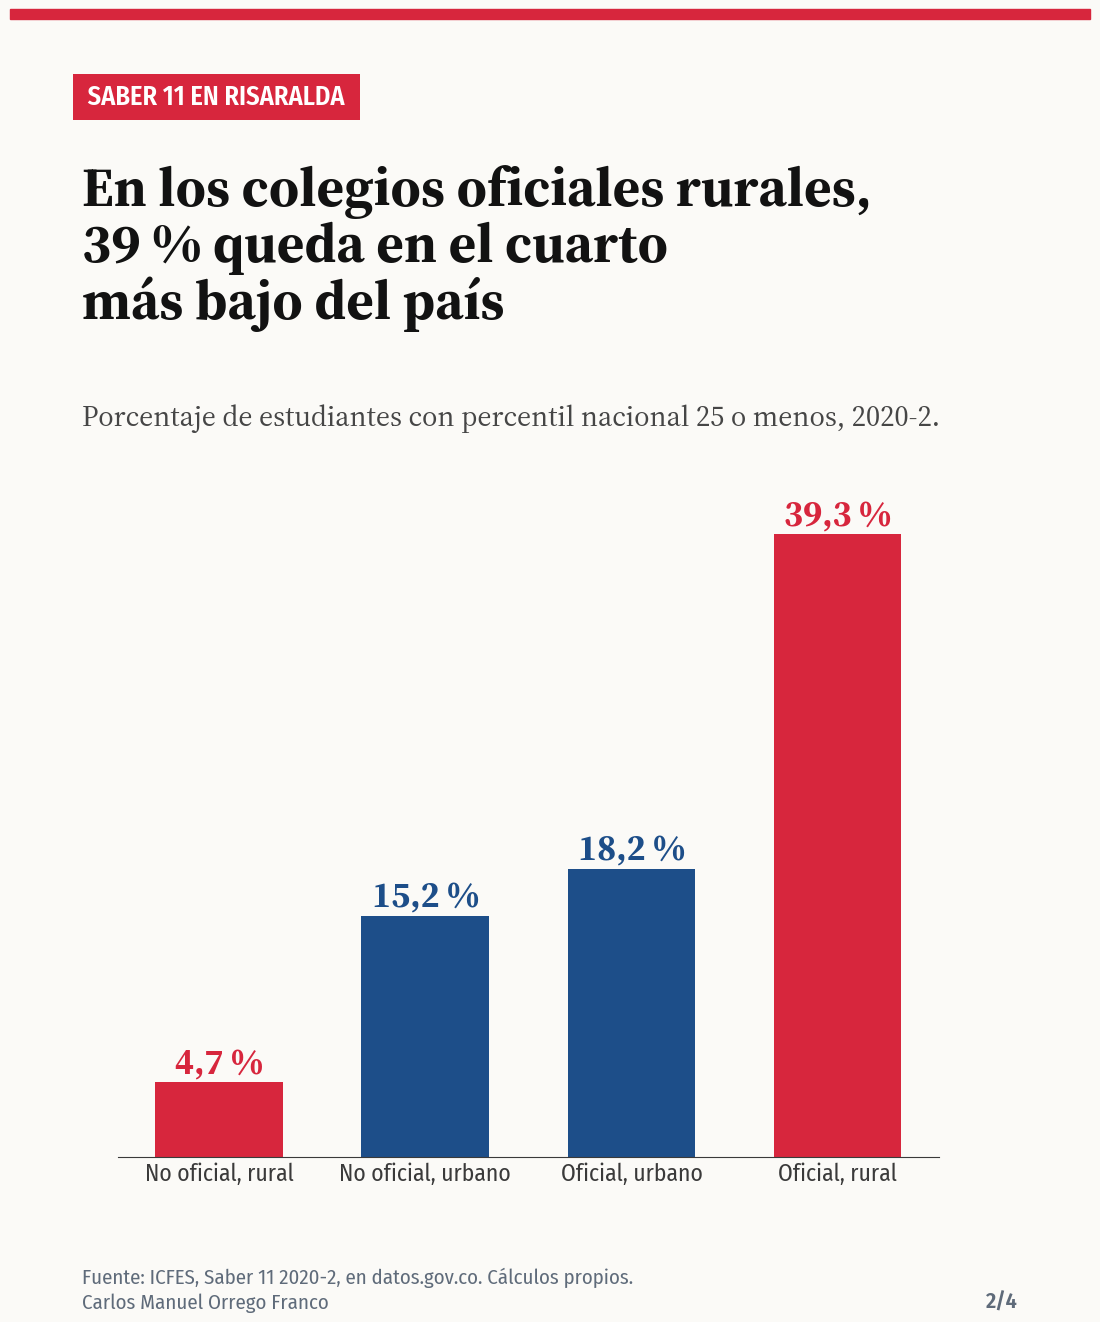

In [95]:
from taller import carrusel as c
c.preparar_fuentes()
PIE = "Fuente: ICFES, Saber 11 2020-2, en datos.gov.co. Cálculos propios.\nCarlos Manuel Orrego Franco"
zona = paneles["Colegio y zona"].query("n >= 50")["tasa"].round(1)      # grupos con muy pocos estudiantes no van al post
c.lamina_barras(zona.to_dict(), {k: (c.ROJO if "rural" in k else c.AZUL) for k in zona.index}, "SABER 11 EN RISARALDA",
                f"En los colegios oficiales rurales,\n{zona.max():.0f} % queda en el cuarto\nmás bajo del país",
                "Porcentaje de estudiantes con percentil nacional 25 o menos, 2020-2.", PIE, "2/4", "icfes_2.png")
plt.show()

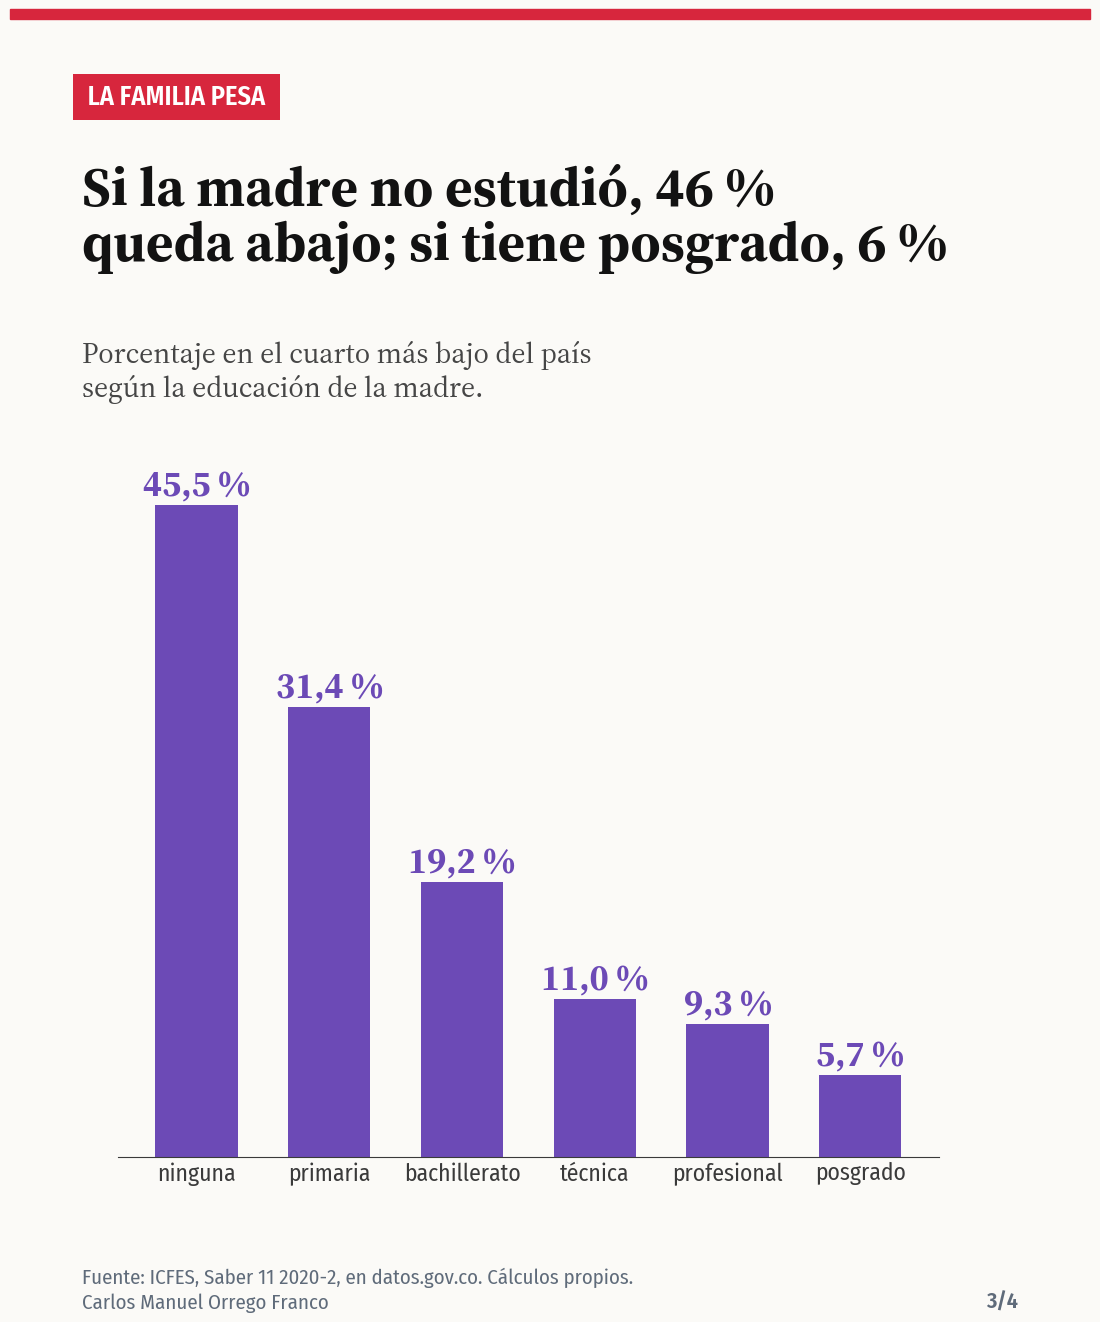

In [96]:
madre_tasa = paneles["Educación de la madre"]["tasa"].round(1)
c.lamina_barras(madre_tasa.to_dict(), {k: c.MORADO for k in madre_tasa.index}, "LA FAMILIA PESA",
                f"Si la madre no estudió, {madre_tasa.iloc[0]:.0f} %\nqueda abajo; si tiene posgrado, {madre_tasa.iloc[-1]:.0f} %",
                "Porcentaje en el cuarto más bajo del país\nsegún la educación de la madre.", PIE, "3/4", "icfes_3.png")
plt.show()

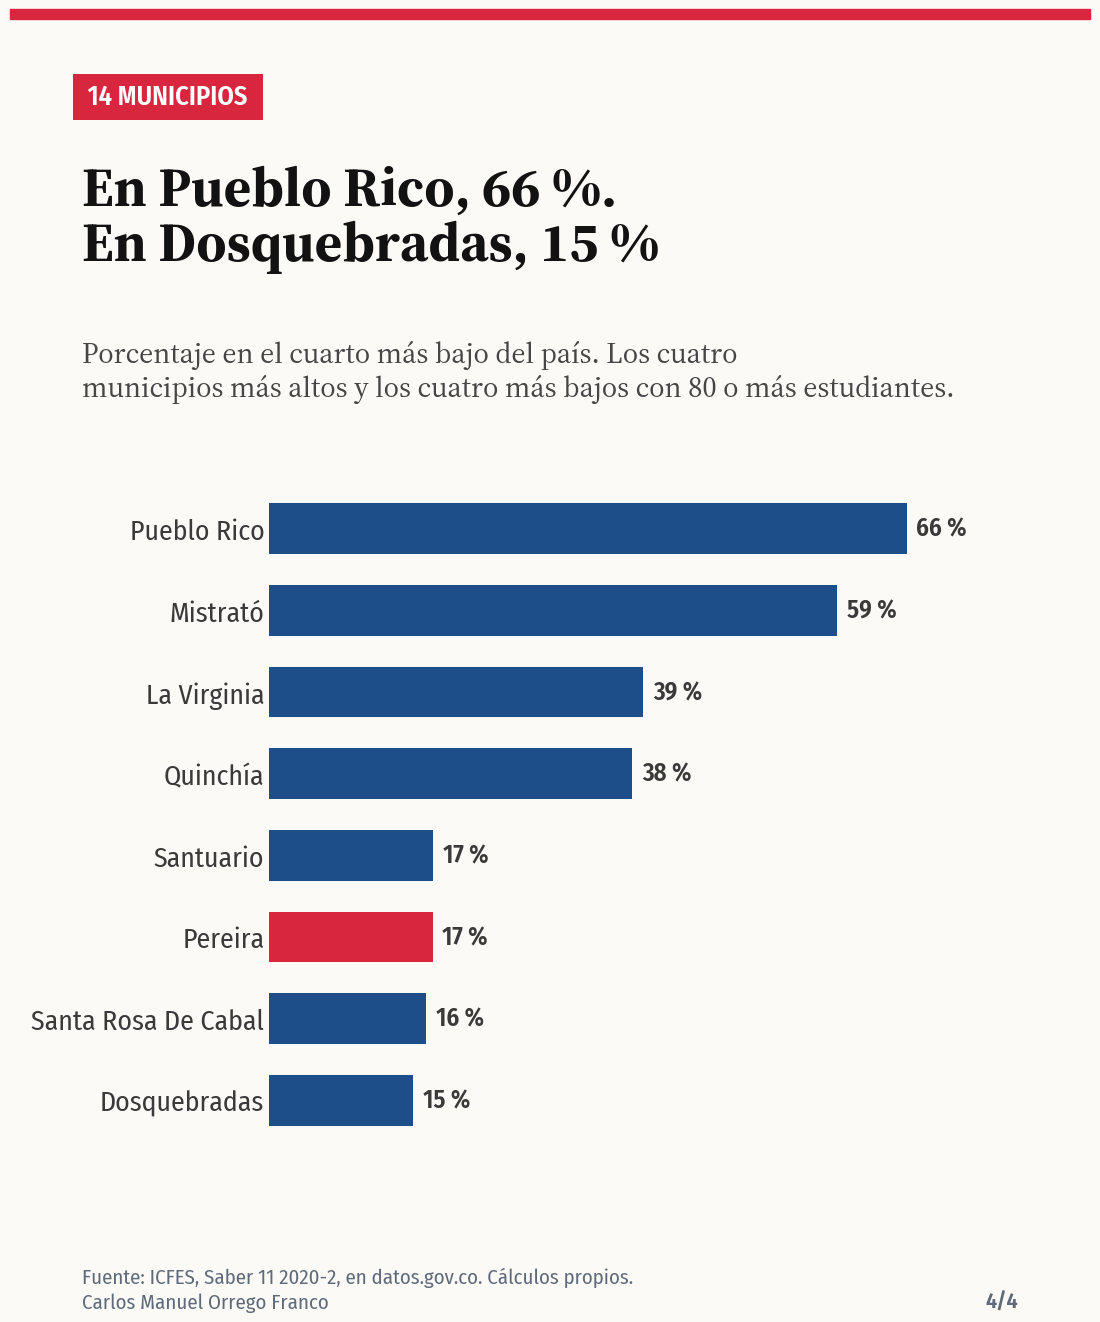

In [97]:
extremos = pd.concat([municipios.nlargest(4, "tasa"), municipios.nsmallest(4, "tasa")]).sort_values("tasa")
c.lamina_ranking(extremos["tasa"], f"{datos['cole_mcpio_ubicacion'].nunique()} MUNICIPIOS",
                 f"En {extremos['tasa'].idxmax()}, {extremos['tasa'].max():.0f} %.\nEn {extremos['tasa'].idxmin()}, {extremos['tasa'].min():.0f} %",
                 "Porcentaje en el cuarto más bajo del país. Los cuatro\nmunicipios más altos y los cuatro más bajos con 80 o más estudiantes.",
                 PIE, "4/4", "icfes_4.png", resaltar=["Pereira"])
plt.show()

## Bitácora

| Decisión | Alternativa | Por qué |
|---|---|---|
| Cuarto más bajo = percentil nacional 25 o menos | Otro corte | El cupo alcanza para uno de cada cuatro |
| Quitar solo los puntajes en cero | Borrar filas con faltantes | Los que dejan preguntas en blanco no se parecen a los demás |
| Llenar faltantes con la mediana del entrenamiento | La mediana de todos | Usar la prueba para llenar sería mirar el examen |
| Tramos por colegio | Por estudiante | Los compañeros de colegio se parecen |
| Captación como métrica | Exactitud | La exactitud premia decir que nadie queda abajo |

## Cambien una línea

Pongan otro departamento en `DEPARTAMENTO` (por ejemplo `"RISARALDA"` o `"CHOCO"`, como lo escribe el ICFES) y corran todo. ¿Las brechas son las mismas?

In [98]:
procedencia()

{'saber11_departamento-CALDAS': {'titulo': 'Saber 11 2020-2: resultados anonimizados por estudiante, un departamento',
  'fuente': 'ICFES, en datos.gov.co, conjunto rnvb-vnyh',
  'origen': 'fuente oficial',
  'descargado': '2026-11-24 23:18 UTC',
  'filas': 9942,
  'md5': '043703a5d378fa58a56f20701b756d93'},
 'saber11': {'titulo': 'Saber 11 2020-2: resultados anonimizados por estudiante, un departamento',
  'fuente': 'ICFES, en datos.gov.co, conjunto rnvb-vnyh',
  'origen': 'fuente oficial',
  'descargado': '2026-11-25 01:10 UTC',
  'filas': 9326,
  'md5': '4c1d326db2d0ecc94acb1cbafe5d23d3',
  'variante': 'saber11_departamento-RISARALDA'},
 'saber11_departamento-CHOCO': {'titulo': 'Saber 11 2020-2: resultados anonimizados por estudiante, un departamento',
  'fuente': 'ICFES, en datos.gov.co, conjunto rnvb-vnyh',
  'origen': 'fuente oficial',
  'descargado': '2026-11-25 00:36 UTC',
  'filas': 4303,
  'md5': 'b34872050667047a4f06133eb5811ead'},
 'saber11_departamento-RISARALDA': {'titulo